<a href="https://colab.research.google.com/github/Stephanie490/DATA201-labs/blob/main/Neural_Network_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12 Lab: Your First Neural Network

**Goal:** see for yourself what a hidden layer adds, using the same "will the student pass?" idea from class.

**The data:** 600 students. For each one we know `hours_studied`, `hours_slept`, and whether they `passed` (1) or not (0).
The pattern is *not* a straight line: studying helps, but only if you are also reasonably rested.

**What you will do**
1. Load and look at the data
2. Fit **one neuron** (logistic regression) and see where it fails
3. Fit a **small neural network** and see the improvement
4. Look inside: count the weights
5. Experiment: hidden units and learning rate

In [ ]:
# Mount Google Drive, then read the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

# CHANGE THIS to the folder where you saved student_pass.csv in your Drive
path = '/content/drive/MyDrive/Data_201/Datasets/student_pass.csv'
df = pd.read_csv(path)
df.head()

,hours_studied,hours_slept,passed
0,7.7,6.8,1
1,4.4,9.1,0
2,8.6,10.2,1
3,7.0,8.8,1
4,0.9,10.7,0


## Step 1: Look at the data
Always look before you model. How many students? How many passed?

(600, 3)
passed
0    358
1    242
Name: count, dtype: int64


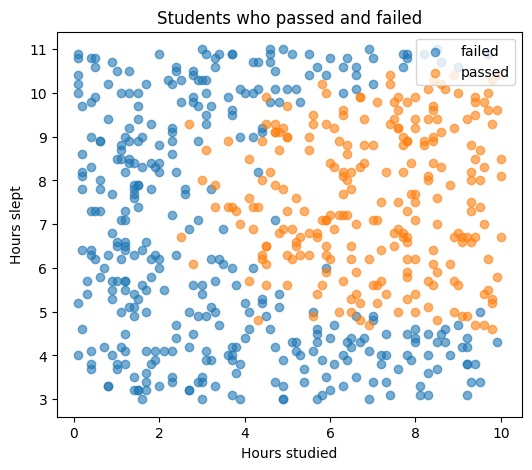

In [ ]:
print(df.shape)
print(df['passed'].value_counts())

plt.figure(figsize=(6, 5))
plt.scatter(df.hours_studied[df.passed == 0], df.hours_slept[df.passed == 0], c='tab:blue', label='failed', alpha=0.6)
plt.scatter(df.hours_studied[df.passed == 1], df.hours_slept[df.passed == 1], c='tab:orange', label='passed', alpha=0.6)
plt.xlabel('Hours studied')
plt.ylabel('Hours slept')
plt.legend()
plt.title('Students who passed and failed')
plt.show()

**Question 1:** Look at the picture. Could you separate the orange dots from the blue dots with **one straight line**? Why or why not?


## Step 2: Split and scale
Two things from class:
- Keep a **test set** that the model never sees while learning.
- **Scale** the inputs (mean 0, standard deviation 1). Neural networks need this.
We learn the scaling from the training data only, then apply the same scaling to the test data.

In [ ]:
X = df[['hours_studied', 'hours_slept']]
y = df['passed']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)


scaler = StandardScaler().fit(X_train)       # learn mean and std from training data only

# Standardize training data: (value - mean) / standard deviation
X_train_s = scaler.transform(X_train)


# Standardize test data using the SAME mean and standard deviation from training
# This prevents data leakage
X_test_s = scaler.transform(X_test)

### A helper to draw decision regions
This function colors the plane by what the model predicts.

In [ ]:
def show_model(model, title):
    # draw predictions on a grid of (hours studied, hours slept) values
    g1, g2 = np.meshgrid(np.linspace(0, 10, 200), np.linspace(3, 11, 200))
    grid = pd.DataFrame({'hours_studied': g1.ravel(), 'hours_slept': g2.ravel()})
    pred = model.predict(scaler.transform(grid)).reshape(g1.shape)
    plt.figure(figsize=(6, 5))
    plt.contourf(g1, g2, pred, alpha=0.25, cmap='coolwarm', levels=[-0.5, 0.5, 1.5])
    plt.scatter(X_train.hours_studied[y_train == 0], X_train.hours_slept[y_train == 0], c='tab:blue', s=15)
    plt.scatter(X_train.hours_studied[y_train == 1], X_train.hours_slept[y_train == 1], c='tab:orange', s=15)
    plt.xlabel('Hours studied')
    plt.ylabel('Hours slept')
    plt.title(title)
    plt.show()

## Step 3: One neuron (logistic regression)
Logistic regression is a weighted sum followed by a sigmoid: **one neuron**, no hidden layer. Mathematically, it takes the inputs, multiplies them by learned weights, adds a bias, and applies sigmoid to predict a probability. Since there are no hidden layers, its decision boundary is a straight line.

One neuron   train accuracy: 0.756
One neuron   test accuracy:  0.787


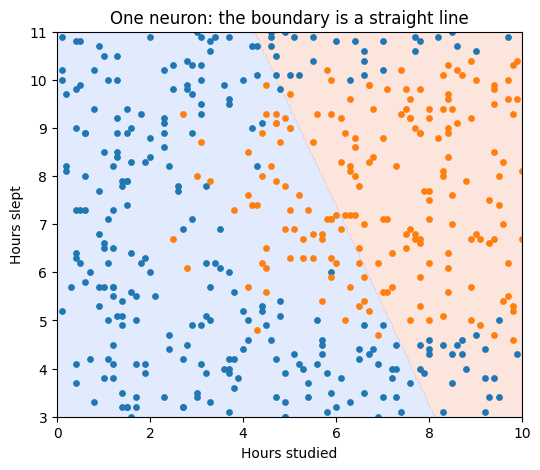

In [ ]:
one_neuron = LogisticRegression()
one_neuron.fit(X_train_s, y_train)

print("One neuron   train accuracy:", round(one_neuron.score(X_train_s, y_train), 3))
print("One neuron   test accuracy: ", round(one_neuron.score(X_test_s, y_test), 3))
show_model(one_neuron, 'One neuron: the boundary is a straight line')

**Question 2:** What shape is the boundary? Does it match the orange region well?
*Your answer:*

## Step 4: A neural network with one hidden layer
Now add a **hidden layer of 5 neurons**. Each hidden neuron does a weighted sum, then ReLU. The output neuron combines them.

- `hidden_layer_sizes=(5,)` means one hidden layer with 5 units
- `max_iter` is the maximum number of **epochs** *
- `random_state` fixes the random starting weights so everyone gets the same answer

*One epoch means the neural network has gone through the entire training dataset once. During each epoch, the network uses the data to update its weights and improve predictions. Training may stop earlier if the model converges (stops improving sufficiently).
For example, max_iter= 2000 allows the network to go through the training dataset up to 2,000 times.

*Adam automatically adjusts the learning rate for each weight to help minimize the loss function efficiently.

Neural net   train accuracy: 0.907
Neural net   test accuracy:  0.94


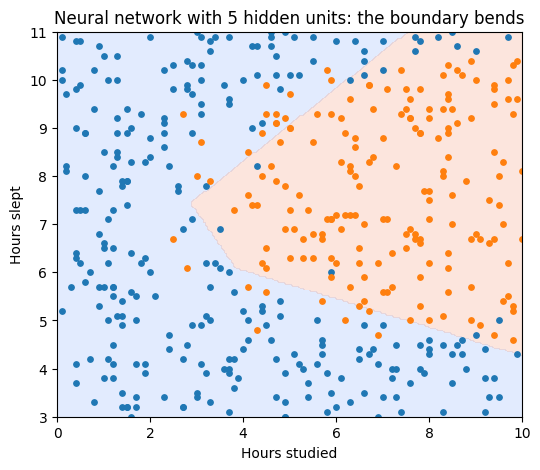

In [ ]:
net = MLPClassifier(hidden_layer_sizes=(5,),  # MLP =Multilayer Perceptron. by default it uses mini batches. #MLPRegressor for regression.
                    activation='relu',
                    solver='adam',
                    max_iter=2000,
                    random_state=0)
net.fit(X_train_s, y_train)

print("Neural net   train accuracy:", round(net.score(X_train_s, y_train), 3))
print("Neural net   test accuracy: ", round(net.score(X_test_s, y_test), 3))
show_model(net, 'Neural network with 5 hidden units: the boundary bends')

**Question 3:** Compare the test accuracy of the one neuron and the neural network. Which is better, and by how much? What changed in the picture?
*Your answer:*

## Step 5: Look inside, count the weights
In class: parameters in a layer = (inputs + 1) × units. Let's check that against the real model.
`coefs_` holds the weights and `intercepts_` holds the biases.

In [ ]:
for i, (W, b) in enumerate(zip(net.coefs_, net.intercepts_)):
    print(f"Layer {i + 1}: weights {W.shape} + biases {b.shape}  ->  {W.size + b.size} parameters")

total = sum(W.size + b.size for W, b in zip(net.coefs_, net.intercepts_))
print("Total parameters:", total)
print("By formula:", (2 + 1) * 5 + (5 + 1) * 1)

Layer 1: weights (2, 5) + biases (5,)  ->  15 parameters
Layer 2: weights (5, 1) + biases (1,)  ->  6 parameters
Total parameters: 21
By formula: 21


- Input layer: 2 features (no trainable parameters in this layer).
- Layer 1 (Hidden layer): 5 neurons, with 10 weights + 5 biases = 15 parameters.
- Layer 2 (Output layer): 1 neuron, with 5 weights + 1 bias = 6 parameters.

## Step 6: How many hidden units do we need?
Same network, different numbers of hidden units. Watch the accuracy and the boundary.

hidden units | train acc | test acc
           1 |     0.753 |    0.787
           2 |     0.760 |    0.787
           5 |     0.907 |    0.940
          20 |     0.944 |    0.920


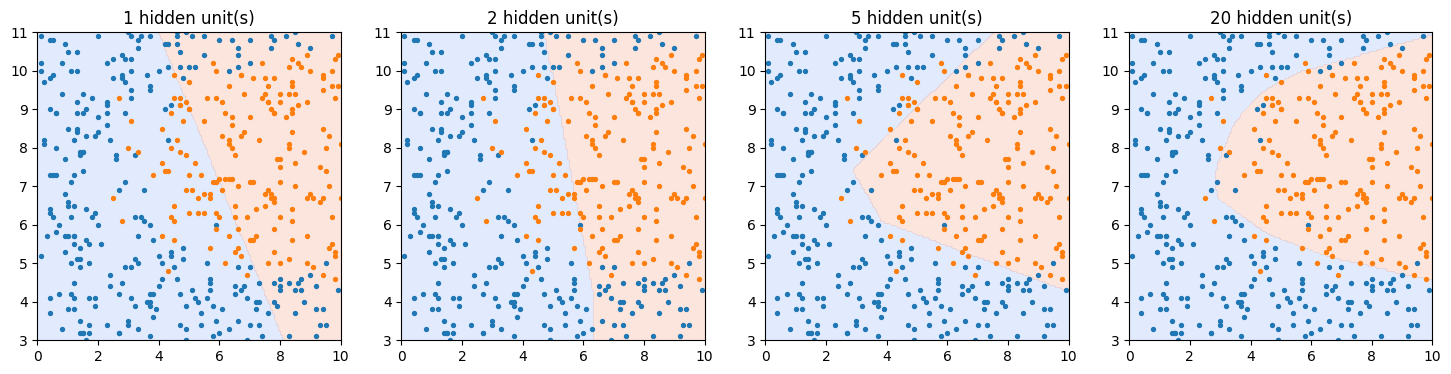

In [ ]:
#Step 1: Setting up

sizes = [1, 2, 5, 20] #Set the number of hidden neurons

fig, axes = plt.subplots(1, 4, figsize=(18, 4)) #Create four plots (one for each network)

#Create a grid of points for drawing decision boundaries
g1, g2 = np.meshgrid(np.linspace(0, 10, 150), np.linspace(3, 11, 150))

#Scale the grid using the same scaler as the training data
grid_s = scaler.transform(pd.DataFrame({
    'hours_studied': g1.ravel(),
    'hours_slept': g2.ravel()
}))


#Step 2: Train and Evaluate

print("hidden units | train acc | test acc")

for ax, k in zip(axes, sizes):

    m = MLPClassifier(
        hidden_layer_sizes=(k,),
        max_iter=3000,
        random_state=0
    ).fit(X_train_s, y_train)

    # Calculate training and testing accuracy
    tr = m.score(X_train_s, y_train)
    te = m.score(X_test_s, y_test)

    # Display accuracy results
    print(f"{k:>12} | {tr:9.3f} | {te:8.3f}")

#Step 3

#Plot the decision boundary for each network
    ax.contourf(
        g1, g2,
        m.predict(grid_s).reshape(g1.shape),
        alpha=0.25,
        cmap='coolwarm',
        levels=[-0.5, 0.5, 1.5]
    )

 #Plot the training observations (two classes)
    ax.scatter(
        X_train.hours_studied[y_train == 0],
        X_train.hours_slept[y_train == 0],
        c='tab:blue', s=8
    )

    ax.scatter(
        X_train.hours_studied[y_train == 1],
        X_train.hours_slept[y_train == 1],
        c='tab:orange', s=8
    )

    ax.set_title(f"{k} hidden unit(s)")

plt.show()

**Question 4:** What happens with 1 hidden unit? Does 20 units give a much better test accuracy than 5? Which size would you choose, and why?

**Try it:** change `sizes` to `[3, 10, 50, 100]` and run again.
*Your answer:*

## Step 7: Watching the network learn
Training is gradient descent: each epoch the weights are nudged to make the **loss** smaller.
`loss_curve_` stores the loss after every epoch. The **learning rate** is the size of each nudge (the ρ from class).

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


learning rate  0.0001: test accuracy 0.427


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


learning rate   0.001: test accuracy 0.833


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


learning rate    0.01: test accuracy 0.940
learning rate     0.1: test accuracy 0.927


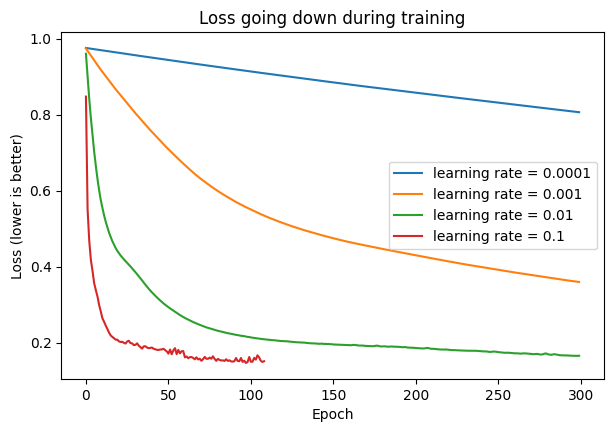

In [ ]:
plt.figure(figsize=(7, 4.5))

for lr in [0.0001, 0.001, 0.01, 0.1]:
    m = MLPClassifier(hidden_layer_sizes=(5,),
                      learning_rate_init=lr,
                      max_iter=300,
                      random_state=0)
    m.fit(X_train_s, y_train)      # (a warning about not converging is normal here)
    plt.plot(m.loss_curve_, label=f"learning rate = {lr}")

    print(f"learning rate {lr:>7}: test accuracy {m.score(X_test_s, y_test):.3f}")


plt.xlabel('Epoch')
plt.ylabel('Loss (lower is better)')
plt.legend()
plt.title('Loss going down during training')
plt.show()

The warning means:
The neural network reached the maximum number of training epochs (max_iter=300), but the loss had not stopped improving enough to meet the stopping criterion.

**Question 5:** Which learning rate is too small (barely learns in 300 epochs)? What changes can we make to reduce the convergence warnings?

*Your answer:*

## Step 8: Use the model on new students
Two new students:
- **Student A** studied 8 hours and slept 7.5 hours.
- **Student B** studied 8 hours but slept only 4 hours.

What do the one neuron and the neural network predict? (Each prints the probability of passing.)

In [ ]:
new = pd.DataFrame({'hours_studied': [8, 8], 'hours_slept': [7.5, 4]}, index=['Student A', 'Student B'])
new_s = scaler.transform(new)

print("Probability of passing")
print("One neuron:    ", one_neuron.predict_proba(new_s)[:, 1].round(2))
print("Neural network:", net.predict_proba(new_s)[:, 1].round(2))

Probability of passing
One neuron:     [0.76 0.55]
Neural network: [0.99 0.13]


Logistic regression (one neuron):
- Predicts a 76% probability of passing for Student A.
- Predicts a 55% probability for Student B.
- Uses a linear combination of study hours and sleep hours to make predictions.

Neural network (hidden layer):
- Predicts a 99% probability for Student A.
- Predicts only a 13% probability for Student B.
- Can learn nonlinear relationships between studying, sleeping, and passing.

**Question 6:** Which model captures the idea that studying a lot does not help if you barely sleep? Why can a hidden layer capture it but one neuron cannot?
*Your answer:*

---
## Wrap-up
- One neuron = a straight-line boundary.
- A hidden layer lets the boundary **bend**.
- More hidden units = more flexibility; there is a point of diminishing returns.
- Training = gradient descent on the loss; the learning rate controls the step size.